In [2]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
IMAGE_DIR = RAW_DIR / "IMG"
CSV_PATH = RAW_DIR / "driving_log.csv"
OUT_DIR = PROJECT_ROOT / "data" / "processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)

IMG_HEIGHT, IMG_WIDTH = 66, 200
CROP_TOP, CROP_BOTTOM = 0.35, 0.10
CAMERA_CORRECTION = 0.20

print("Project:", PROJECT_ROOT)
print("CSV exists:", CSV_PATH.exists())
print("Images folder exists:", IMAGE_DIR.exists())

Project: C:\Users\user\Neuro Drive
CSV exists: True
Images folder exists: True


In [3]:
columns = ["center", "left", "right", "steering", "throttle", "brake", "speed"]

# Load CSV
df = pd.read_csv(CSV_PATH, header=None, names=columns)

# Convert numerical columns
for col in ["steering", "throttle", "brake", "speed"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")


# Resolve image paths
def resolve_path(value):
    filename = str(value).strip().replace("\\", "/").split("/")[-1]
    return IMAGE_DIR / filename


# Update existing columns instead of creating duplicates
for col in ["center", "left", "right"]:
    df[col] = df[col].apply(resolve_path)

# Display results
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
display(df.head())

Rows: 5490
Columns: ['center', 'left', 'right', 'steering', 'throttle', 'brake', 'speed']


,center,left,right,steering,throttle,brake,speed
0,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.0,0,0.000002
1,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.0,0,0.000014
2,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.0,0,0.000018
3,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.0,0,0.000002
4,C:\Users\user\Neuro Drive\data\raw\IMG\center_...,C:\Users\user\Neuro Drive\data\raw\IMG\left_20...,C:\Users\user\Neuro Drive\data\raw\IMG\right_2...,0.0,0.0,0,0.000020


In [4]:
numeric_missing = df[["steering", "throttle", "brake", "speed"]].isna().any(axis=1)
image_missing = pd.Series(False, index=df.index)
for col in ["center", "left", "right"]:
    image_missing |= ~df[col].apply(lambda p: p.is_file())

invalid = numeric_missing | image_missing
print("Invalid rows:", int(invalid.sum()))
df = df.loc[~invalid].copy().reset_index(drop=True)

outside = ~df["steering"].between(-1, 1)
print("Steering outside [-1, 1]:", int(outside.sum()))
if outside.any():
    display(df.loc[outside, ["center", "steering"]].head())
    raise ValueError("Inspect steering values outside [-1, 1] before proceeding.")

print("Valid records:", len(df))

Invalid rows: 0
Steering outside [-1, 1]: 0
Valid records: 5490


In [5]:
# First: separate 70% training and 30% temporary data
train_df, temp_df = train_test_split(
    df,
    test_size=0.40,
    random_state=SEED,
    shuffle=True
)

# Second: divide temporary data equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    shuffle=True
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 3294
Validation: 1098
Testing: 1098


Shape: (66, 200, 3) | dtype: uint8


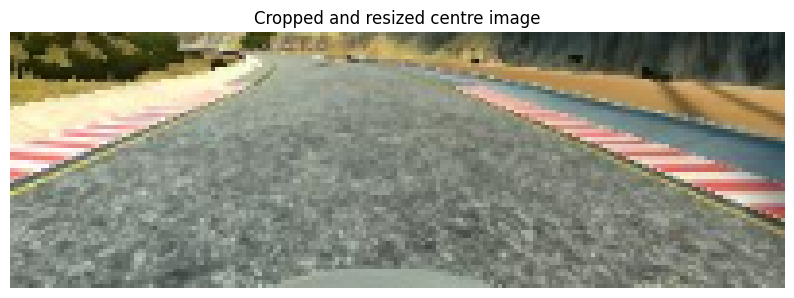

In [6]:
def preprocess_image(image):
    if image is None:
        raise ValueError("Image could not be decoded.")

    h, w = image.shape[:2]
    top = int(h * CROP_TOP)
    bottom = int(h * (1 - CROP_BOTTOM))
    image = image[top:bottom, :, :]
    image = cv2.resize(image, (IMG_WIDTH, IMG_HEIGHT),
                       interpolation=cv2.INTER_AREA)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return image  # uint8, shape (66, 200, 3)

def load_image(path):
    image = cv2.imread(str(path))
    if image is None:
        raise FileNotFoundError(f"Cannot read image: {path}")
    return preprocess_image(image)

def normalize_image(image):
    # NVIDIA-style scaling to approximately [-0.5, 0.5].
    return image.astype(np.float32) / 255.0 - 0.5

sample = load_image(train_df.loc[1, "center"])
print("Shape:", sample.shape, "| dtype:", sample.dtype)
plt.figure(figsize=(10, 4))
plt.imshow(sample)
plt.title("Cropped and resized centre image")
plt.axis("off");
plt.show()

In [7]:
def choose_camera(row, correction=CAMERA_CORRECTION):
    camera = random.choice(["center", "left", "right"])
    steering = float(row["steering"])

    if camera == "left":
        steering += correction
    elif camera == "right":
        steering -= correction

    return row[f"{camera}"], float(np.clip(steering, -1, 1)), camera


def flip_horizontal(image, steering):
    return cv2.flip(image, 1), -float(steering)


def change_brightness(image, low=0.75, high=1.25):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[:, :, 2] *= random.uniform(low, high)
    hsv[:, :, 2] = np.clip(hsv[:, :, 2], 0, 255)
    return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)


def translate_image(image, steering, max_shift=20, steering_per_pixel=0.002):
    h, w = image.shape[:2]
    shift = random.randint(-max_shift, max_shift)
    matrix = np.float32([[1, 0, shift], [0, 1, 0]])
    shifted = cv2.warpAffine(
        image, matrix, (w, h), borderMode=cv2.BORDER_REPLICATE
    )
    # Approximate label correction; tune conservatively.
    steering += shift * steering_per_pixel
    return shifted, float(np.clip(steering, -1, 1))


def augment_training_row(row, use_side_cameras=True):
    if use_side_cameras:
        path, steering, camera = choose_camera(row)
    else:
        path, steering, camera = row["center"], float(row["steering"]), "center"

    image = load_image(path)

    if random.random() < 0.5:
        image, steering = flip_horizontal(image, steering)
    if random.random() < 0.5:
        image = change_brightness(image)
    if random.random() < 0.5:
        image, steering = translate_image(image, steering)

    return image, float(np.clip(steering, -1, 1)), camera

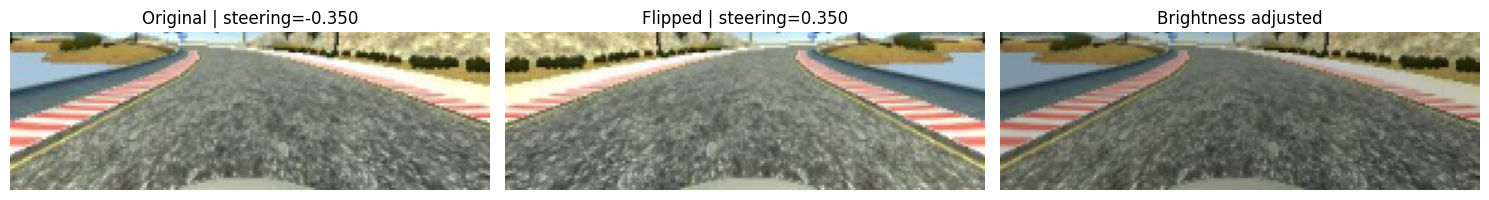

In [9]:
row = train_df.iloc[8]
original = load_image(row["center"])
original_steering = float(row["steering"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(original)
axes[0].set_title(f"Original | steering={original_steering:.3f}")
flipped, flipped_steering = flip_horizontal(original, original_steering)
axes[1].imshow(flipped)
axes[1].set_title(f"Flipped | steering={flipped_steering:.3f}")
bright = change_brightness(original)
axes[2].imshow(bright)
axes[2].set_title("Brightness adjusted")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

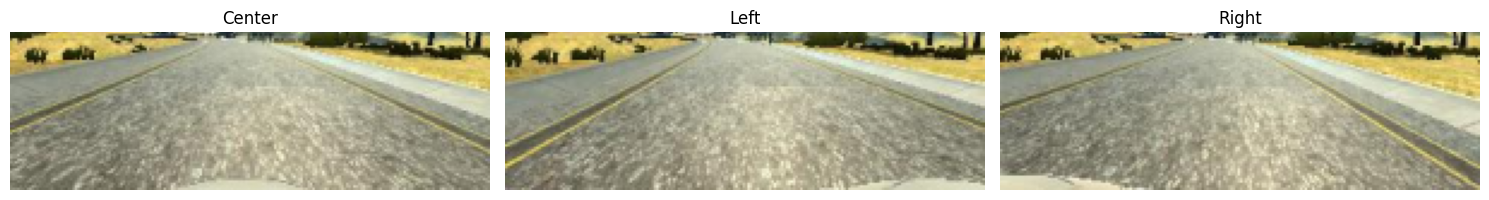

Original steering: 0.0
Left camera corrected: 0.2
Right camera corrected: -0.2


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, camera in zip(axes, ["center", "left", "right"]):
    ax.imshow(load_image(row[f"{camera}"]))
    ax.set_title(camera.capitalize())
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Original steering:", original_steering)
print("Left camera corrected:", np.clip(original_steering + CAMERA_CORRECTION, -1, 1))
print("Right camera corrected:", np.clip(original_steering - CAMERA_CORRECTION, -1, 1))

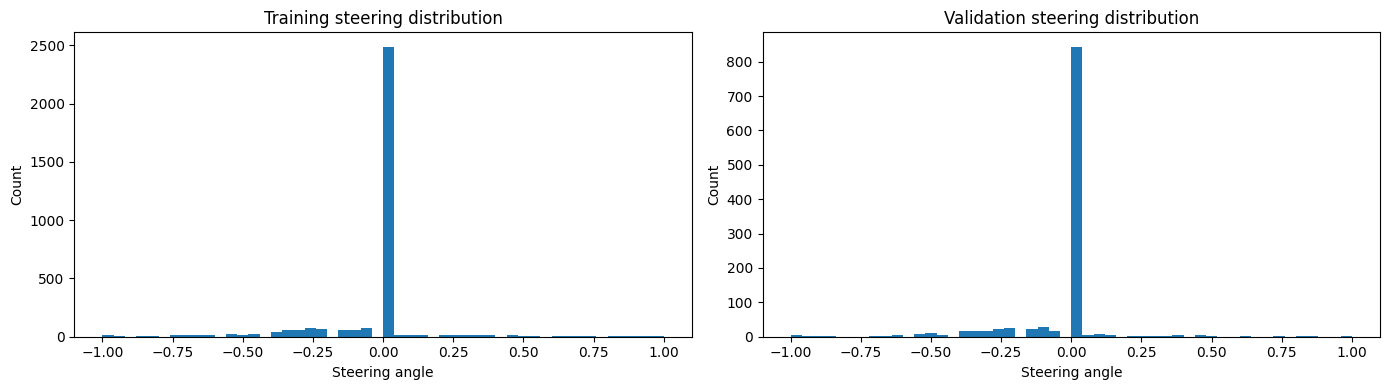

Training zero-steering fraction: 0.7553126897389193
Validation zero-steering fraction: 0.76775956284153
Sampling weights calculated (mean): 0.6803642987249545


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(train_df["steering"], bins=50)
axes[0].set_title("Training steering distribution")
axes[1].hist(val_df["steering"], bins=50)
axes[1].set_title("Validation steering distribution")
for ax in axes:
    ax.set_xlabel("Steering angle")
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

print("Training zero-steering fraction:", (train_df.steering == 0).mean())
print("Validation zero-steering fraction:", (val_df.steering == 0).mean())

# Optional per-row weights to reduce dominance of common steering bins.
# We will decide whether to use these when building the training generator.
edges = np.linspace(-1, 1, 26)
bins = pd.cut(train_df["steering"], bins=edges, include_lowest=True, labels=False)
counts = bins.value_counts()
weights_by_bin = 1.0 / counts
weights = bins.map(weights_by_bin).astype(float)
weights = (weights / weights.mean()).clip(upper=5.0)
train_df["sampling_weight"] = weights
print("Sampling weights calculated (mean):", train_df["sampling_weight"].mean())

In [21]:
# Save paths and labels. Training augmentation will be applied dynamically later.
train_manifest = train_df[
    ["center", "left", "right", "steering", "throttle", "sampling_weight"]
].copy()

val_manifest = val_df[
    ["center", "left", "right", "steering", "throttle"]
].copy()

test_manifest = test_df[
    ["center", "left", "right", "steering", "throttle"]
].copy()

for frame in [train_manifest, val_manifest, test_manifest]:
    for col in ["center", "left", "right"]:
        frame[col] = frame[col].astype(str)

train_manifest.to_csv(OUT_DIR / "train_manifest.csv", index=False)
val_manifest.to_csv(OUT_DIR / "validation_manifest.csv", index=False)
test_manifest.to_csv(OUT_DIR / "test_manifest.csv",index=False)

print("Saved training validation and test manifests.")

Saved training validation and test manifests.


In [22]:
# Preprocess only centre-camera validation images; no augmentation.
X_val = np.stack([load_image(p) for p in val_df["center"]]).astype(np.uint8)
y_val = val_df["steering"].to_numpy(dtype=np.float32)

np.savez_compressed(
    OUT_DIR / "validation_data.npz",
    X_val=X_val,
    y_val=y_val
)

print("X_val:", X_val.shape, X_val.dtype)
print("y_val:", y_val.shape, y_val.dtype)
print("Saved:", OUT_DIR / "validation_data.npz")

X_val: (1098, 66, 200, 3) uint8
y_val: (1098,) float32
Saved: C:\Users\user\Neuro Drive\data\processed\validation_data.npz
